<a href="https://colab.research.google.com/github/ivansuarez-AU/MAI510_M3_Assignment_3_2/blob/main/MAI510_M3_Assignment_3_2_LSTM_BoW_Qwen_Flask_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAI 510 · Module 3 · Assignment 3.2
## StreamSense AI — The AI Showdown: Baseline, LSTM, Qwen and Flask
**Instructor + student Google Colab notebook** | Full graded comparison: **bag-of-words vs LSTM** | Optional additional **Qwen3 through Ollama** | Flask prediction application | Dashboard | Word report | ZIP.

**Important:** This is **Assignment 3.2**, not 3.1. For the graded comparison, the same held-out IMDB test set must be evaluated by the two neural models. Ollama/Qwen is a separately identified, optional exploration. Running in short demo mode **does not** qualify as a final full assessment. No actual scores are pre-filled.

**Before you start:** Have your completed Assignment 3.1 ZIP available; the notebook can import its `LSTM_sequence_200.keras`. If unavailable, a clearly labeled fallback trains a new LSTM using the same data split, which takes longer.


## LAB 0 — Required student registration
Enter a real first and last name and the assignment. You can use a fictional StreamSense AI business scenario; academic results must come from your executed models.

In [1]:
from pathlib import Path
import os, re, sys, json, zipfile, time, subprocess, shutil, urllib.request, urllib.error, platform
from datetime import datetime, timezone
STUDENT_NAME=input('Full student name (e.g., Ivan Suarez): ').strip()
while len(STUDENT_NAME.split())<2:
    print('Please enter first and last name.')
    STUDENT_NAME=input('Full student name: ').strip()
ASSIGNMENT_NAME=input('Assignment (press Enter for Assignment 3.2): ').strip() or 'Assignment 3.2'
if '3.2' not in ASSIGNMENT_NAME:
    raise ValueError('This notebook supports Assignment 3.2; enter Assignment 3.2.')
COURSE='MAI 510 — Deep Learning'
SAFE_NAME=re.sub(r'[^A-Za-z0-9]+','_',STUDENT_NAME).strip('_')
RUN_ID=datetime.now().strftime('%Y%m%d_%H%M%S')
OUT=Path('/content')/f'MAI510_M3_A32_{SAFE_NAME}_{RUN_ID}'
OUT.mkdir(parents=True,exist_ok=True)
print('REGISTERED:',STUDENT_NAME,'|',ASSIGNMENT_NAME,'|',OUT)


Full student name (e.g., Ivan Suarez): Ivan Suarez
Assignment (press Enter for Assignment 3.2): Assignment 3.2
REGISTERED: Ivan Suarez | Assignment 3.2 | /content/MAI510_M3_A32_Ivan_Suarez_20261111_011537


## LAB 1 — Setup, demo/final settings and fair comparison rules
- Demo mode uses smaller train/validation/test subsets for live teaching. **Final mode must use the same full settings as Assignment 3.1** (seed 42; 18,000 training, 4,000 validation and the full 25,000-test set).
- To compare to 3.1, match `VOCAB_SIZE`, `BASE_LENGTH`, `SEED`, `TRAIN_LIMIT`, `VALID_LIMIT`, and `TEST_LIMIT` to the prior run. If 3.1 was run with other settings, edit them here and document the changes.
- Choose/deploy LSTM as required; compare it fairly with a bag-of-words baseline. Judge hyperparameters using validation, not the final test set. No student data are sent to cloud services outside dataset downloads and optional Ollama model downloads.

In [2]:
%pip -q install python-docx plotly scikit-learn pandas matplotlib flask
import numpy as np, pandas as pd, matplotlib.pyplot as plt, tensorflow as tf
import plotly.express as px, plotly.graph_objects as go
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from IPython.display import display, HTML
from time import perf_counter
DEMO_MODE=True               # Set False and run all cells for graded final submission
SEED=42
VOCAB_SIZE=10000
BASE_LENGTH=200
EMBED_DIM=32; LSTM_UNITS=32
BATCH_SIZE=64
TRAIN_LIMIT=3000 if DEMO_MODE else 18000
VALID_LIMIT=600 if DEMO_MODE else 4000
TEST_LIMIT=2500 if DEMO_MODE else None
EPOCH_BUDGET=2 if DEMO_MODE else 8
np.random.seed(SEED);tf.keras.utils.set_random_seed(SEED)
print('TensorFlow',tf.__version__,'GPU',tf.config.list_physical_devices('GPU'))
print('MODE:', 'SHORT INSTRUCTOR DEMO — not final' if DEMO_MODE else 'FULL STUDENT EXPERIMENT')


TensorFlow 2.21.0 GPU [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
MODE: SHORT INSTRUCTOR DEMO — not final


## LAB 2 — Load the SAME IMDB split as Assignment 3.1
The IMDB dataset supplies integer-encoded reviews and binary labels. This code intentionally reproduces the 3.1 split. **Keep the training/validation split identical when comparing models.**

In [3]:
(raw_x,raw_y),(raw_xt,raw_yt)=imdb.load_data(num_words=VOCAB_SIZE)
raw_y=np.asarray(raw_y);raw_yt=np.asarray(raw_yt)
rng=np.random.default_rng(SEED)
indices=rng.permutation(len(raw_x))
valid_idx=indices[:VALID_LIMIT];train_idx=indices[VALID_LIMIT:VALID_LIMIT+TRAIN_LIMIT]
test_idx=np.arange(len(raw_xt)) if TEST_LIMIT is None else np.arange(TEST_LIMIT)
train_reviews=[raw_x[int(i)] for i in train_idx]
valid_reviews=[raw_x[int(i)] for i in valid_idx]
test_reviews=[raw_xt[int(i)] for i in test_idx]
y_train=raw_y[train_idx];y_valid=raw_y[valid_idx];y_test=raw_yt[test_idx]
Xtr_seq=pad_sequences(train_reviews,maxlen=BASE_LENGTH,padding='post',truncating='pre')
Xva_seq=pad_sequences(valid_reviews,maxlen=BASE_LENGTH,padding='post',truncating='pre')
Xte_seq=pad_sequences(test_reviews,maxlen=BASE_LENGTH,padding='post',truncating='pre')
word_index=imdb.get_word_index()
reverse_index={i+3:w for w,i in word_index.items()}
reverse_index.update({0:'<PAD>',1:'<START>',2:'<UNK>',3:'<UNUSED>'})
def decode_review(seq,limit=None):
    words=[reverse_index.get(int(i),'<UNK>') for i in seq]
    return ' '.join(words if limit is None else words[:limit])
print('Train',len(train_reviews),'Valid',len(valid_reviews),'Held-out test',len(test_reviews))
assert not set(train_idx).intersection(set(valid_idx))
print('Sample:',decode_review(test_reviews[0],35),'| label:',int(y_test[0]))


17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train 3000 Valid 600 Held-out test 2500
Sample: <START> please give this one a miss br br <UNK> <UNK> and the rest of the cast rendered terrible performances the show is flat flat flat br br i don't know how michael madison could | label: 0


## LAB 3 — Import the saved LSTM from Assignment 3.1
Choose and upload the **3.1 ZIP** or a directly saved `.keras` file. The notebook checks that a saved model exists and can load. When a file is absent, choose the transparent fallback in Lab 4. **An imported model must have been trained with the same data split and preprocessing settings**; confirm this from your 3.1 experiment metadata and report.

In [4]:
from google.colab import files
IMPORT_A31=True               # Set False if rerunning 3.2 standalone
A31_MODEL_PATH=None
A31_IMPORT_NOTE='No previous model imported'
A31_PRIOR_METADATA={}
if IMPORT_A31:
    print('Upload your Assignment 3.1 ZIP or LSTM_sequence_200.keras; Cancel if none.')
    uploaded=files.upload()
    if uploaded:
        upload_name=next(iter(uploaded))
        source=Path('/content')/upload_name
        if source.suffix.lower()=='.zip':
            target=OUT/'a31_import';target.mkdir(exist_ok=True)
            with zipfile.ZipFile(source) as z:
                manifest_names=[i for i in z.namelist() if Path(i).name=='RUN_EVIDENCE_MANIFEST.json']
                if manifest_names:
                    A31_PRIOR_METADATA=json.loads(z.read(manifest_names[0]))
                    print('Earlier experiment mode:',A31_PRIOR_METADATA.get('mode'))
                    if not DEMO_MODE and 'DEMO' in str(A31_PRIOR_METADATA.get('mode','')).upper():
                        raise ValueError('Full Assignment 3.2 requires the FULL Assignment 3.1 model, not a demo-trained model.')
                else:
                    print('WARNING: A3.1 metadata absent. Manually verify matching prior training split and demo/full mode.')
                candidates=[item for item in z.infolist() if not item.is_dir() and Path(item.filename).name==f'LSTM_sequence_{BASE_LENGTH}.keras']
                if not candidates:raise FileNotFoundError(f'No LSTM_sequence_{BASE_LENGTH}.keras in uploaded ZIP')
                # Read exactly the expected model file; never blindly extract an untrusted archive
                A31_MODEL_PATH=target/f'LSTM_sequence_{BASE_LENGTH}.keras'
                A31_MODEL_PATH.write_bytes(z.read(candidates[0]))
        elif source.suffix.lower()=='.keras':
            A31_MODEL_PATH=source
        else:
            raise ValueError('Upload a ZIP or .keras model file')
        A31_IMPORT_NOTE=f'Imported file: {upload_name}'
        print(A31_IMPORT_NOTE,'| selected model:',A31_MODEL_PATH)


Upload your Assignment 3.1 ZIP or LSTM_sequence_200.keras; Cancel if none.


Saving LSTM_sequence_200.keras to LSTM_sequence_200.keras
Imported file: LSTM_sequence_200.keras | selected model: /content/LSTM_sequence_200.keras


## LAB 4 — Load the LSTM or train a clearly labeled replacement
The architecture matches the 3.1 reference: `Embedding(10000,32)` → `LSTM(32)` → sigmoid. Reuse your actual saved 3.1 model whenever possible. Missing model is not silently replaced; the printed evidence will say **FALLBACK RETRAINED**.

In [5]:
def make_lstm():
    m=tf.keras.Sequential([tf.keras.layers.Input(shape=(BASE_LENGTH,)),
        tf.keras.layers.Embedding(VOCAB_SIZE,EMBED_DIM,mask_zero=True),
        tf.keras.layers.LSTM(LSTM_UNITS),tf.keras.layers.Dense(1,activation='sigmoid')])
    m.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])
    return m
LSTM_TRAIN_SECONDS=None
if A31_MODEL_PATH is not None:
    lstm_model=tf.keras.models.load_model(str(A31_MODEL_PATH))
    LSTM_ORIGIN='IMPORTED ASSIGNMENT 3.1'
    if A31_PRIOR_METADATA:
        print('Prior run metadata available; verify its settings match this run:', A31_PRIOR_METADATA.get('mode'))
    if lstm_model.input_shape[-1]!=BASE_LENGTH:
        raise ValueError('Imported sequence length does not match BASE_LENGTH')
else:
    LSTM_ORIGIN='FALLBACK RETRAINED IN ASSIGNMENT 3.2'
    tf.keras.utils.set_random_seed(SEED)
    lstm_model=make_lstm()
    cb=tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=2,restore_best_weights=True)
    t0=perf_counter()
    lstm_history=lstm_model.fit(Xtr_seq,y_train,validation_data=(Xva_seq,y_valid),
                   epochs=EPOCH_BUDGET,batch_size=BATCH_SIZE,callbacks=[cb],verbose=1)
    LSTM_TRAIN_SECONDS=perf_counter()-t0
lstm_model.summary()
lstm_model.save(OUT/'lstm_for_flask.keras')
print('SOURCE:',LSTM_ORIGIN,'| elapsed training seconds:',LSTM_TRAIN_SECONDS)


Model: "Sentiment_LSTM_200"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 985,061 (3.76 MB)

 Trainable params: 328,353 (1.25 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 656,708 (2.51 MB)

SOURCE: IMPORTED ASSIGNMENT 3.1 | elapsed training seconds: None


## LAB 5 — Build a simple, fair bag-of-words (BoW) baseline
The same tokenized reviews are converted into **binary presence vectors** (`multi_hot`). Word order is lost. A compact Dense model is used so students can explain the tradeoff. BoW features use the same 10,000-token vocabulary and train/validation/test split; they do **not** use LSTM padded sequences.

In [6]:
def multi_hot(reviews,n_words=VOCAB_SIZE):
    arr=np.zeros((len(reviews),n_words),dtype=np.float32)
    for i,seq in enumerate(reviews):
        valid=np.asarray(seq,dtype=np.int32)
        valid=valid[(valid>=4)&(valid<n_words)]
        if len(valid):arr[i,np.unique(valid)]=1.0
    return arr
print('Constructing presence matrices (float32):')
Xtr_bow=multi_hot(train_reviews)
Xva_bow=multi_hot(valid_reviews)
Xte_bow=multi_hot(test_reviews)
print('BoW shapes:',Xtr_bow.shape,Xva_bow.shape,Xte_bow.shape)
print('Memory consideration: test BoW matrix can be large for the full 25,000 reviews.')


Constructing presence matrices (float32):
BoW shapes: (3000, 10000) (600, 10000) (2500, 10000)
Memory consideration: test BoW matrix can be large for the full 25,000 reviews.


## LAB 6 — Train the baseline and track early stopping
Use validation loss to select weights; never choose a winner based on its test-set performance alone.

In [7]:
tf.keras.utils.set_random_seed(SEED)
bow_model=tf.keras.Sequential([tf.keras.layers.Input(shape=(VOCAB_SIZE,)),
    tf.keras.layers.Dense(64,activation='relu'),tf.keras.layers.Dense(1,activation='sigmoid')],name='BoW_dense')
bow_model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])
cb=tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=2,restore_best_weights=True)
t0=perf_counter()
bow_history=bow_model.fit(Xtr_bow,y_train,validation_data=(Xva_bow,y_valid),
    epochs=EPOCH_BUDGET,batch_size=BATCH_SIZE,callbacks=[cb],verbose=1)
BOW_TRAIN_SECONDS=perf_counter()-t0
bow_model.save(OUT/'bow_baseline.keras')
bow_model.summary()
print('Baseline train time:',round(BOW_TRAIN_SECONDS,2),'seconds')


Epoch 1/2
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - accuracy: 0.7607 - loss: 0.5097 - val_accuracy: 0.8633 - val_loss: 0.3470
Epoch 2/2
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9480 - loss: 0.1827 - val_accuracy: 0.8733 - val_loss: 0.3025


Model: "BoW_dense"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │       640,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,920,389 (7.33 MB)

 Trainable params: 640,129 (2.44 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,280,260 (4.88 MB)

Baseline train time: 3.99 seconds


## LAB 7 — Grade-required: evaluate BOTH models on exactly the same held-out test examples
Accuracy, precision, recall, F1 and confusion matrices are generated from observed predictions. The LSTM training time is only available if trained here; otherwise consult your own 3.1 training log. **Do not invent it.**

,Model,Accuracy,Precision,Recall,F1,Parameters,Training seconds
0,Bag-of-words Dense,0.8652,0.8780,0.8331,0.8549,640129,3.9869
1,LSTM,0.8060,0.8503,0.7198,0.7796,328353,NaN


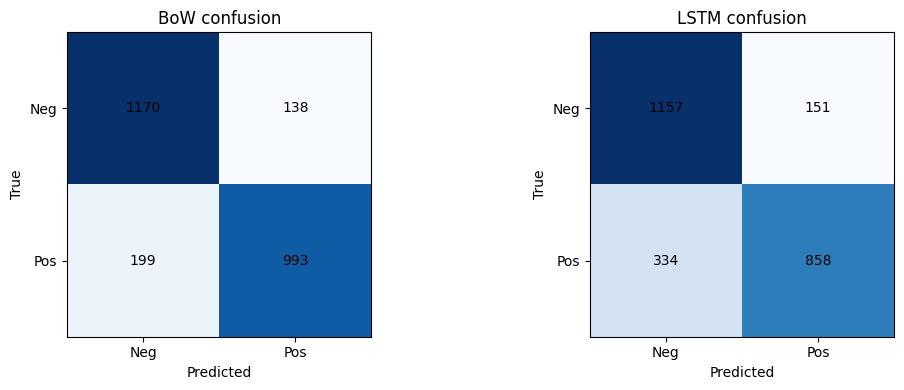

In [8]:
lstm_prob=lstm_model.predict(Xte_seq,batch_size=256,verbose=0).reshape(-1)
bow_prob=bow_model.predict(Xte_bow,batch_size=256,verbose=0).reshape(-1)
lstm_pred=(lstm_prob>=0.5).astype(int);bow_pred=(bow_prob>=0.5).astype(int)
def score_row(name,pred):
    return {'Model':name,'Accuracy':accuracy_score(y_test,pred),
        'Precision':precision_score(y_test,pred,zero_division=0),
        'Recall':recall_score(y_test,pred,zero_division=0),
        'F1':f1_score(y_test,pred,zero_division=0)}
model_compare=pd.DataFrame([score_row('Bag-of-words Dense',bow_pred),score_row('LSTM',lstm_pred)])
model_compare['Parameters']=[bow_model.count_params(),lstm_model.count_params()]
model_compare['Training seconds']=[BOW_TRAIN_SECONDS,LSTM_TRAIN_SECONDS]
model_compare.to_csv(OUT/'REQUIRED_bow_vs_lstm_full_test_metrics.csv',index=False)
display(model_compare.round(4))
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,name,pred in zip(axs,['BoW','LSTM'],[bow_pred,lstm_pred]):
    c=confusion_matrix(y_test,pred,labels=[0,1]);ax.imshow(c,cmap='Blues')
    ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['Neg','Pos'],yticklabels=['Neg','Pos'],xlabel='Predicted',ylabel='True',title=name+' confusion')
    for (r,k),value in np.ndenumerate(c):ax.text(k,r,str(value),ha='center',va='center')
fig.tight_layout();fig.savefig(OUT/'REQUIRED_both_confusion_matrices.png',dpi=165);plt.show()


## LAB 8 — Training curves and explainability discussion
The baseline's training curves are available in this run. Imported 3.1 LSTM curves live in the 3.1 submission; don't invent a new curve for a model that was loaded from file.

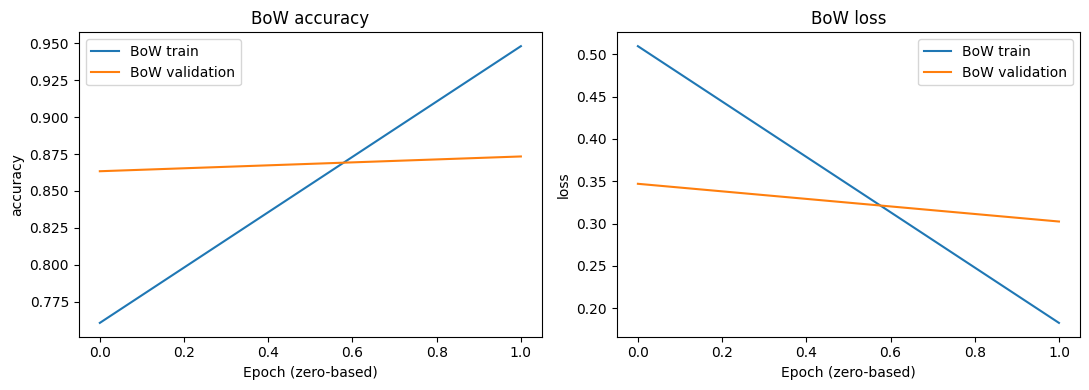

In [9]:
fig,ax=plt.subplots(1,2,figsize=(11,4))
for j,metric in enumerate(['accuracy','loss']):
    ax[j].plot(bow_history.history[metric],label='BoW train')
    ax[j].plot(bow_history.history['val_'+metric],label='BoW validation')
    ax[j].set(xlabel='Epoch (zero-based)',ylabel=metric,title=f'BoW {metric}')
    ax[j].legend()
fig.tight_layout();fig.savefig(OUT/'REQUIRED_bow_training_curves.png',dpi=165);plt.show()


## LAB 9 — Time predictions fairly: warmed-up, repeatable inference
These are **local model inference** times in the Colab runtime, not end-to-end internet service latency. Compare CPU/GPU environments carefully. Model inference for a batch of examples may be different from a single review. Use the same list of held-out review indices for both models.

In [10]:
TIMING_ITEMS=20 if DEMO_MODE else 100
chosen=np.linspace(0,len(y_test)-1,num=min(TIMING_ITEMS,len(y_test)),dtype=int)
# Prepare batches once to exclude preprocessing for model-only inference
a=Xte_bow[chosen];b=Xte_seq[chosen]
for _ in range(3):
    _=bow_model(a,training=False).numpy();_=lstm_model(b,training=False).numpy()
def time_model(model,data,reps=5):
    trials=[]
    for _ in range(reps):
        t0=perf_counter();_=model(data,training=False).numpy()
        trials.append((perf_counter()-t0)/len(data)*1000)
    return float(np.median(trials)),trials
bow_ms,bow_runs=time_model(bow_model,a)
lstm_ms,lstm_runs=time_model(lstm_model,b)
latency_df=pd.DataFrame([{'Model':'Bag-of-words Dense','Median milliseconds per review':bow_ms,'N':len(chosen)},
                         {'Model':'LSTM','Median milliseconds per review':lstm_ms,'N':len(chosen)}])
latency_df.to_csv(OUT/'REQUIRED_model_inference_latency.csv',index=False)
display(latency_df.round(3))
print('Model-only timings; do not call these Flask HTTP round-trip times.')


,Model,Median milliseconds per review,N
0,Bag-of-words Dense,0.190,20
1,LSTM,0.857,20


Model-only timings; do not call these Flask HTTP round-trip times.


## LAB 10 — Build five *different* challenging reviews and compare both trained models
Optional fun challenge within the improved 3.2 rubric; not a replacement for the required IMDB test-set comparison. Subjective intended labels should be reviewed by humans. **Text input encoding is an approximation** of the original Keras IMDB data pipeline, so note the potential gap.

In [11]:
def encode_new_text(text):
    tokens=re.findall(r"[a-z]+(?:'[a-z]+)?",text.lower())
    return [1]+[min(VOCAB_SIZE-1,word_index.get(w,-1)+3) if w in word_index and word_index[w]+3<VOCAB_SIZE else 2 for w in tokens]
def infer_both_text(text):
    seq=encode_new_text(text)
    lstm_x=pad_sequences([seq],maxlen=BASE_LENGTH,padding='post',truncating='pre')
    bow_x=multi_hot([seq]);p1=float(lstm_model(lstm_x,training=False).numpy().ravel()[0]);p2=float(bow_model(bow_x,training=False).numpy().ravel()[0])
    return {'LSTM positive probability':p1,'LSTM sentiment':'Positive' if p1>=.5 else 'Negative',
            'BoW positive probability':p2,'BoW sentiment':'Positive' if p2>=.5 else 'Negative'}
challenge_reviews=[
  'I thought I would hate the movie, but I absolutely loved it.',
  'What a masterpiece of boredom. I nearly fell asleep.',
  'The acting was wonderful, but the ending ruined the whole film.',
  'Not a bad movie at all; in fact I would happily watch it again.',
  'The first hour was terrible. The final scene was unexpectedly brilliant.'
]
challenge_df=pd.DataFrame([{'Review':t,**infer_both_text(t)} for t in challenge_reviews]);display(challenge_df)
challenge_df.to_csv(OUT/'OPTIONAL_fool_the_ai_two_models.csv',index=False)


,Review,LSTM positive probability,LSTM sentiment,BoW positive probability,BoW sentiment
0,"I thought I would hate the movie, but I absolu...",0.632792,Positive,0.632972,Positive
1,What a masterpiece of boredom. I nearly fell a...,0.593922,Positive,0.483377,Negative
2,"The acting was wonderful, but the ending ruine...",0.496152,Negative,0.466370,Negative
3,Not a bad movie at all; in fact I would happil...,0.354533,Negative,0.405447,Negative
4,The first hour was terrible. The final scene w...,0.377956,Negative,0.477261,Negative


## LAB 11 — Interactive dashboard: evidence for the executive discussion
Dashboard values come from the actual metrics and timings calculated above. Export a self-contained HTML file for the assignment.

In [12]:
metric_long=model_compare.melt(id_vars='Model',value_vars=['Accuracy','Precision','Recall','F1'],var_name='Metric',value_name='Score')
fig1=px.bar(metric_long,x='Metric',y='Score',color='Model',barmode='group',range_y=[0,1],title='Held-out test: BoW versus LSTM')
fig2=px.bar(latency_df,x='Model',y='Median milliseconds per review',title='Warm inference time per example (same runtime)')
html='<html><head><meta charset="utf-8"></head><body><h1>MAI 510 · Assignment 3.2 · '+STUDENT_NAME+'</h1>'
html+='<p>Mode: '+('DEMO (NOT FINAL)' if DEMO_MODE else 'FULL')+'</p>'
html+=fig1.to_html(full_html=False,include_plotlyjs=True)
html+=fig2.to_html(full_html=False,include_plotlyjs=False)
html+='</body></html>'
(OUT/'REQUIRED_comparison_dashboard.html').write_text(html,encoding='utf-8')
fig1.show();fig2.show()


## LAB 12 — Flask web application: real upload/POST workflow **inside Colab**
Flask needs the SAME saved `.keras` model and the identical vocabulary/sequence settings. The downloadable `flask_app/` files will be generated, then the Flask `/predict` route will be tested with `app.test_client()` directly in Colab. A successful **test-client request does not mean the app has a public browser URL**. To browse the site in a normal browser, download and run the app locally or use a supported deployment host.

In [13]:
from pathlib import Path
FLASK_DIR=OUT/'flask_app';TEMPLATE_DIR=FLASK_DIR/'templates';TEMPLATE_DIR.mkdir(parents=True,exist_ok=True)
import shutil
shutil.copy2(OUT/'lstm_for_flask.keras',FLASK_DIR/'lstm_for_flask.keras')
metadata={'vocab_size':VOCAB_SIZE,'sequence_length':BASE_LENGTH,'model':'lstm_for_flask.keras',
          'labels':['Negative','Positive'],'preprocessing_note':'Approximate word-level regex tokenizer; Keras IMDB raw review encoding differs from arbitrary text.'}
(FLASK_DIR/'model_config.json').write_text(json.dumps(metadata,indent=2))
(FLASK_DIR/'word_index.json').write_text(json.dumps(word_index))
(FLASK_DIR/'requirements.txt').write_text('flask>=3.0,<4\ntensorflow>=2.15\nnumpy>=1.26\n')
flask_py=r"""from flask import Flask, request, jsonify, render_template
import os, json, re
from pathlib import Path
import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences
HERE=Path(__file__).resolve().parent
config=json.loads((HERE/'model_config.json').read_text())
word_index=json.loads((HERE/'word_index.json').read_text())
model=tf.keras.models.load_model(str(HERE/config['model']))
app=Flask(__name__)
MAX_CHARS=8000

def encode(text):
    toks=re.findall(r"[a-z]+(?:'[a-z]+)?",text.lower())
    ids=[1]
    for token in toks:
        idx=word_index.get(token)
        ids.append(idx+3 if idx is not None and idx+3<config['vocab_size'] else 2)
    return pad_sequences([ids],maxlen=config['sequence_length'],padding='post',truncating='pre')

@app.get('/')
def home():return render_template('index.html')

@app.get('/health')
def health():return jsonify({'status':'ok','model':config['model']})

@app.post('/predict')
def predict():
    data=request.get_json(silent=True) if request.is_json else request.form
    text=str((data or {}).get('review','')).strip()
    if not text:return jsonify({'error':'A review is required'}),400
    if len(text)>MAX_CHARS:return jsonify({'error':'Review exceeds 8000 characters'}),400
    p=float(model(encode(text),training=False).numpy().ravel()[0])
    sentiment='Positive' if p>=0.5 else 'Negative'
    return jsonify({'sentiment':sentiment,'confidence':round(p if p>=.5 else 1-p,4),
                    'positive_probability':round(p,4),'note':config['preprocessing_note']})

if __name__=='__main__':
    app.run(host='127.0.0.1',port=int(os.environ.get('PORT','5000')),debug=False)
"""
(FLASK_DIR/'app.py').write_text(flask_py)
html_template="""<!doctype html><html><head><meta charset="utf-8"><title>StreamSense AI</title><style>body{font-family:system-ui;max-width:750px;margin:60px auto;padding:20px}textarea{width:100%;height:170px}button{padding:12px 20px}pre{white-space:pre-wrap;background:#eee;padding:18px;border-radius:8px}</style></head><body><h1>StreamSense AI — Movie Sentiment</h1><p>MAI 510: Student-trained LSTM, not a cloud API.</p><textarea id="review">I expected a bad movie, but I enjoyed it.</textarea><p><button onclick="classify()">Classify sentiment</button></p><pre id="result">Submit a review to see the prediction.</pre><script>async function classify(){const review=document.getElementById('review').value;let r=await fetch('/predict',{method:'POST',headers:{'Content-Type':'application/json'},body:JSON.stringify({review})});document.getElementById('result').textContent=JSON.stringify(await r.json(),null,2)}</script></body></html>"""
(TEMPLATE_DIR/'index.html').write_text(html_template)
print('Generated:',FLASK_DIR,'files:',[str(p.relative_to(FLASK_DIR)) for p in FLASK_DIR.rglob('*') if p.is_file()])


Generated: /content/MAI510_M3_A32_Ivan_Suarez_20261111_011537/flask_app files: ['requirements.txt', 'lstm_for_flask.keras', 'model_config.json', 'app.py', 'word_index.json', 'templates/index.html']


In [16]:

# ============================================================
# MAI 510 - MODULE 3 - ASSIGNMENT 3.2
# FLASK TEMPLATE REPAIR - GOOGLE COLAB
# ============================================================

from pathlib import Path
from jinja2 import FileSystemLoader
import importlib.util

flask_dir = Path(FLASK_DIR).resolve()
app_file = flask_dir / "app.py"
template_dir = flask_dir / "templates"
template_file = template_dir / "index.html"

print("=" * 65)
print("STREAMSENSE AI - FLASK TEMPLATE REPAIR")
print("=" * 65)

# Verify the expected files
print("App exists:", app_file.exists())
print("Template exists:", template_file.exists())
print("Template directory:", template_dir)

if not app_file.exists():
    raise FileNotFoundError(f"Missing Flask app: {app_file}")

if not template_file.exists():
    raise FileNotFoundError(f"Missing template: {template_file}")

# Import the Flask application
spec = importlib.util.spec_from_file_location(
    "stream_app_repaired",
    str(app_file)
)

module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

app = module.app

# FIX: Set the actual Jinja loader, not just template_folder
app.jinja_env.loader = FileSystemLoader(str(template_dir))

# Confirm template resolution BEFORE making HTTP requests
template = app.jinja_env.get_template("index.html")

print("\nTemplate loaded successfully!")
print("Template filename:", template.filename)

# Test the application
client = app.test_client()

home = client.get("/")
health = client.get("/health")

valid = client.post(
    "/predict",
    json={"review": "I enjoyed the film and would recommend it."}
)

invalid = client.post(
    "/predict",
    json={"review": ""}
)

print("\nHTTP Test Results")
print("Home page:", home.status_code)
print("Health check:", health.status_code)
print("Valid prediction:", valid.status_code)
print("Empty review:", invalid.status_code)

assert home.status_code == 200, "Home page failed"
assert health.status_code == 200, "Health check failed"
assert valid.status_code == 200, "Prediction failed"
assert invalid.status_code == 400, "Empty input validation failed"

print("\nSUCCESS: ALL FOUR FLASK TESTS PASSED")


STREAMSENSE AI - FLASK TEMPLATE REPAIR
App exists: True
Template exists: True
Template directory: /content/MAI510_M3_A32_Ivan_Suarez_20261111_011537/flask_app/templates

Template loaded successfully!
Template filename: /content/MAI510_M3_A32_Ivan_Suarez_20261111_011537/flask_app/templates/index.html

HTTP Test Results
Home page: 200
Health check: 200
Valid prediction: 200
Empty review: 400

SUCCESS: ALL FOUR FLASK TESTS PASSED


## LAB 13 — Prove Flask works: real test-client HTTP requests
We run the Flask application in-process and exercise `/`, `/health`, and `/predict` (valid and empty requests). This produces evidence JSON. **An HTTP test-client is a functional test**, but it does not open a public endpoint.

In [17]:


# ============================================================
# MAI 510 - MODULE 3 - ASSIGNMENT 3.2
# LAB 13 - VERIFIED FLASK HTTP TESTS
# ============================================================

import importlib.util
import json
from pathlib import Path

import pandas as pd
from IPython.display import display
from jinja2 import FileSystemLoader

flask_dir = Path(FLASK_DIR).resolve()
template_dir = flask_dir / "templates"

spec = importlib.util.spec_from_file_location(
    "stream_app_verified",
    str(flask_dir / "app.py")
)

module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

app = module.app

# Explicitly set Jinja's loader to the correct folder.
app.jinja_env.loader = FileSystemLoader(str(template_dir))

# Test template before HTTP requests.
app.jinja_env.get_template("index.html")

client = app.test_client()

health = client.get("/health")
home = client.get("/")

valid = client.post(
    "/predict",
    json={"review": "I enjoyed the film and would recommend it."}
)

invalid = client.post(
    "/predict",
    json={"review": ""}
)

proof = {
    "student": globals().get("STUDENT_NAME", "Unknown"),
    "assignment": "MAI 510 - Assignment 3.2",
    "home_http_status": home.status_code,
    "health_http_status": health.status_code,
    "health": health.get_json(),
    "predict_http_status": valid.status_code,
    "prediction": valid.get_json(),
    "empty_http_status": invalid.status_code,
    "empty_response": invalid.get_json()
}

output_dir = Path(OUT)
output_dir.mkdir(parents=True, exist_ok=True)

json_path = output_dir / "REQUIRED_flask_http_test_proof.json"
csv_path = output_dir / "REQUIRED_flask_http_tests.csv"

json_path.write_text(json.dumps(proof, indent=2))

tests = pd.DataFrame([
    ["GET /", 200, home.status_code],
    ["GET /health", 200, health.status_code],
    ["POST /predict (valid)", 200, valid.status_code],
    ["POST /predict (empty)", 400, invalid.status_code]
], columns=["Test", "Expected", "Actual"])

tests["Result"] = tests.apply(
    lambda r: "PASS" if r["Expected"] == r["Actual"] else "FAIL",
    axis=1
)

display(tests)

tests.to_csv(csv_path, index=False)

all_passed = (tests["Result"] == "PASS").all()

print("\nEvidence saved:")
print(json_path)
print(csv_path)

if all_passed:
    print("\nALL FLASK HTTP TESTS PASSED")
else:
    print("\nSome tests failed. Review the results above.")


,Test,Expected,Actual,Result
0,GET /,200,200,PASS
1,GET /health,200,200,PASS
2,POST /predict (valid),200,200,PASS
3,POST /predict (empty),400,400,PASS



Evidence saved:
/content/MAI510_M3_A32_Ivan_Suarez_20261111_011537/REQUIRED_flask_http_test_proof.json
/content/MAI510_M3_A32_Ivan_Suarez_20261111_011537/REQUIRED_flask_http_tests.csv

ALL FLASK HTTP TESTS PASSED


## OPTIONAL classroom UI — Gradio inside Colab (Flask remains the graded application)
This provides a live interactive textbox *within the notebook*. It does not replace Flask deployment or HTTP test evidence. To avoid network sharing, no public share URL is requested.


In [18]:
RUN_GRADIO_UI=False  # Set True for interactive class demo; leave False for quick final processing
if RUN_GRADIO_UI:
    import subprocess,sys
    subprocess.check_call([sys.executable,"-m","pip","-q","install","gradio"])
    import gradio as gr
    def predict_for_class(text):
        values=infer_both_text(text)
        return values['LSTM sentiment'], round(values['LSTM positive probability'],4), values['BoW sentiment'], round(values['BoW positive probability'],4)
    demo=gr.Interface(fn=predict_for_class,inputs=gr.Textbox(lines=4,label='Movie review'),
        outputs=[gr.Textbox(label='LSTM sentiment'),gr.Number(label='LSTM positive score'),
                 gr.Textbox(label='BoW sentiment'),gr.Number(label='BoW positive score')],
        title='StreamSense AI — Classroom Sentiment Showdown')
    demo.launch(share=False,inline=True,prevent_thread_lock=True)
else:print('Interactive Gradio demo skipped; Flask assignment remains required.')


Interactive Gradio demo skipped; Flask assignment remains required.


## LAB 14 — Required: compare serving time with the Module 2 CNN
Your earlier Module 2 CNN ran on different image inputs. Enter the actual measured time from your own Module 2 lab; **leave blank if you do not have evidence**. This comparison measures latency, not model quality. Optionally time Flask's `/predict` response in this runtime; it includes HTTP request handling and text preprocessing, but no network transit.

In [19]:
flask_timing=[]
for _ in range(3):client.post('/predict',json={'review':'The movie was excellent.'})
for _ in range(20 if DEMO_MODE else 50):
    s=perf_counter();r=client.post('/predict',json={'review':'The movie was excellent.'});flask_timing.append((perf_counter()-s)*1000)
flask_median_ms=float(np.median(flask_timing))
print('Flask test-client median local request ms:',round(flask_median_ms,3))
# Set this number only using your prior Module 2 experiment; otherwise leave None.
MODULE2_CNN_SERVING_MS=None
serving_df=pd.DataFrame([
    {'Application':'Module 3 LSTM Flask test client','Median ms per prediction':flask_median_ms,'Source':'Measured this run'},
    {'Application':'Module 2 CNN application','Median ms per prediction':MODULE2_CNN_SERVING_MS,'Source':'Student prior Module 2 evidence (blank if unavailable)'}])
serving_df.to_csv(OUT/'REQUIRED_serving_time_comparison.csv',index=False)
display(serving_df)


Flask test-client median local request ms: 13.395


,Application,Median ms per prediction,Source
0,Module 3 LSTM Flask test client,13.394825,Measured this run
1,Module 2 CNN application,NaN,Student prior Module 2 evidence (blank if unav...


## LAB 15 — OPTIONAL: Qwen3 via Ollama, using the *same* review set
Qwen is a third, **ungraded** comparison. Its instruction-following generative inference differs from the neural classifiers. We use 10–20 randomly selected labeled test examples for an **exploratory sample**, not a replacement for the full held-out BoW/LSTM comparison. We preserve Qwen errors, token/text length limits and request times. No Qwen-generated numerical certainty is equated to model sigmoid probability.

**Privacy:** Only public IMDB reviews and fictional challenge reviews should be sent to the local model. Ollama installation and model downloads use network access; disable this section to skip them.

In [20]:
RUN_QWEN=False       # Instructor: change True for optional demonstration
QWEN_MODEL='qwen3:0.6b'
QWEN_N=10 if DEMO_MODE else 20
QWEN_MAX_CHARS=1800
QWEN_TIMEOUT=180
QWEN_READY=False;QWEN_ERROR=''
OLLAMA_URL='http://127.0.0.1:11434'
def ollama_ready():
    try:
        with urllib.request.urlopen(OLLAMA_URL+'/api/tags',timeout=3) as r:return r.status==200
    except Exception:return False
if RUN_QWEN:
    try:
        if shutil.which('ollama') is None:
            script=Path('/tmp/mai510_ollama_install.sh')
            urllib.request.urlretrieve('https://ollama.com/install.sh',script)
            install=subprocess.run(['sh',str(script)],capture_output=True,text=True,timeout=240)
            if install.returncode:raise RuntimeError('Installer: '+install.stdout[-1000:]+install.stderr[-1000:])
        if not ollama_ready():
            log=open(OUT/'OPTIONAL_ollama_server.log','w')
            server=subprocess.Popen(['ollama','serve'],stdout=log,stderr=subprocess.STDOUT,start_new_session=True)
            for _ in range(45):
                if ollama_ready():break
                time.sleep(1)
        if not ollama_ready():raise RuntimeError('Ollama server not responding')
        pull=subprocess.run(['ollama','pull',QWEN_MODEL],capture_output=True,text=True,timeout=1200)
        if pull.returncode:raise RuntimeError('Download: '+pull.stderr[-1200:])
        QWEN_READY=True
        print('Qwen ready:',QWEN_MODEL)
    except Exception as e:
        QWEN_ERROR=str(e)
        (OUT/'OPTIONAL_qwen_setup_error.txt').write_text(QWEN_ERROR)
        print('Optional Qwen setup failed; required assignment can continue:',QWEN_ERROR)
else:print('Optional Qwen comparison skipped.')


Optional Qwen comparison skipped.


## LAB 16 — OPTIONAL: Qwen makes predictions on the same samples as BoW and LSTM
For Qwen, decoded IMDB text may be truncated by a character cap; the LSTM itself has a 200-token input cap. Document this asymmetry. We select random test examples with a fixed seed to avoid deliberately selecting only LSTM errors. Sample accuracy is exploratory, not a comparable full-test benchmark.

In [21]:
QWEN_RESULTS=pd.DataFrame()
if QWEN_READY:
    rng_q=np.random.default_rng(SEED+5)
    ids=rng_q.choice(len(y_test),size=min(QWEN_N,len(y_test)),replace=False)
    q_rows=[]
    for rank,idx in enumerate(ids,1):
        full=decode_review(test_reviews[int(idx)])
        sample=full[:QWEN_MAX_CHARS]
        system='Classify the overall sentiment of the IMDB review. Reply with a single JSON object with keys sentiment (positive or negative) and explanation (one sentence).'
        payload={'model':QWEN_MODEL,'stream':False,'think':False,'format':'json',
                 'messages':[{'role':'system','content':system},{'role':'user','content':sample}],
                 'options':{'temperature':0,'num_predict':150}}
        row={'Test index':int(idx),'True label':int(y_test[idx]),'BoW label':int(bow_pred[idx]),'LSTM label':int(lstm_pred[idx]),
             'LSTM positive probability':float(lstm_prob[idx]),'BoW positive probability':float(bow_prob[idx]),
             'Review excerpt':sample,'Qwen input truncated':len(full)>QWEN_MAX_CHARS}
        try:
            req=urllib.request.Request(OLLAMA_URL+'/api/chat',data=json.dumps(payload).encode('utf-8'),headers={'Content-Type':'application/json'},method='POST')
            t0=perf_counter()
            with urllib.request.urlopen(req,timeout=QWEN_TIMEOUT) as r:
                raw=json.loads(r.read().decode('utf-8'))
            elapsed=perf_counter()-t0
            response=raw.get('message',{}).get('content','')
            obj=json.loads(response)
            sentiment=str(obj.get('sentiment','')).lower().strip()
            if sentiment not in ('positive','negative'):raise ValueError('Expected positive or negative, got '+sentiment)
            row.update({'Qwen label':int(sentiment=='positive'),'Qwen explanation':str(obj.get('explanation','')),
                        'Qwen response seconds':elapsed,'Status':'OK'})
        except Exception as e:
            row.update({'Qwen label':np.nan,'Qwen explanation':'','Qwen response seconds':np.nan,'Status':'ERROR: '+str(e)[:180]})
        q_rows.append(row);print(f'Qwen {rank}/{len(ids)}: {row["Status"]}')
    QWEN_RESULTS=pd.DataFrame(q_rows)
    QWEN_RESULTS.to_csv(OUT/'OPTIONAL_three_model_same_review_predictions.csv',index=False)
    display(QWEN_RESULTS[['Test index','True label','BoW label','LSTM label','Qwen label','Status']])
else:print('No Qwen results produced; core assignment unaffected.')


No Qwen results produced; core assignment unaffected.


## LAB 17 — OPTIONAL: Three-model dashboard, disagreement audit and measured accuracy
Only successful Qwen rows are analyzed; each of the three models is evaluated on **exactly those same rows**. Qwen explanations are generated text, **not** proof of internal reasoning. Do not compare Qwen token-generation latency directly to the inference-only baseline as if the workloads were identical.

In [22]:
QWEN_SUMMARY={}
if not QWEN_RESULTS.empty:
    valid=QWEN_RESULTS[QWEN_RESULTS['Status']=='OK'].copy()
    if len(valid):
        valid['Qwen label']=valid['Qwen label'].astype(int)
        for name,col in [('BoW','BoW label'),('LSTM','LSTM label'),('Qwen','Qwen label')]:
            valid[name+' correct']=valid[col].astype(int)==valid['True label'].astype(int)
        valid['All agree']=(valid['BoW label']==valid['LSTM label']) & (valid['LSTM label']==valid['Qwen label'])
        valid.to_csv(OUT/'OPTIONAL_three_model_annotated_disagreements.csv',index=False)
        QWEN_SUMMARY={'model':QWEN_MODEL,'successes':len(valid),'attempts':len(QWEN_RESULTS),
            'BoW sample accuracy':float(valid['BoW correct'].mean()),'LSTM sample accuracy':float(valid['LSTM correct'].mean()),
            'Qwen sample accuracy':float(valid['Qwen correct'].mean()),'all_agree_rate':float(valid['All agree'].mean()),
            'median_qwen_response_seconds':float(valid['Qwen response seconds'].median()),
            'note':'Random exploratory subset; different preprocessing and latency semantics; not graded.'}
        (OUT/'OPTIONAL_three_model_summary.json').write_text(json.dumps(QWEN_SUMMARY,indent=2))
        ds=pd.DataFrame([{'Model':n,'Selected-sample accuracy':QWEN_SUMMARY[n+' sample accuracy']} for n in ['BoW','LSTM','Qwen']])
        chart=px.bar(ds,x='Model',y='Selected-sample accuracy',range_y=[0,1],title='Same selected reviews: three models (exploratory)')
        chart.write_html(str(OUT/'OPTIONAL_three_model_dashboard.html'),include_plotlyjs=True);chart.show()
        display(valid.loc[~valid['All agree'],['Test index','True label','BoW label','LSTM label','Qwen label','Qwen explanation']])
        print('Exploratory summary:',QWEN_SUMMARY)
    else:print('No successful Qwen calls.')
else:print('Qwen experiment skipped.')


Qwen experiment skipped.


## LAB 18 — Decision prompts: evidence-based student reflection
For the **required** report, write a **1–2 page deployment recommendation**: Did LSTM earn its cost compared with BoW? What changes for 10,000 reviews/day? Use full test metrics and measured inference, not Qwen-selected-sample results. Also address the Module 2 CNN comparison, explicitly stating if that measurement is missing. For optional Qwen, use an appendix or separate reflection.

Report fields below are intentionally empty, and a Word **template** is generated. Students must replace them with their own evidence-based analysis.

In [23]:
EXECUTIVE_RECOMMENDATION=''          # Student: which of BoW and LSTM and WHY? Cite metrics.
COMPARISON_INTERPRETATION=''          # Student: accuracy, precision, recall, F1 and tradeoffs.
LATENCY_INTERPRETATION=''             # Student: per-review ms; 10,000/day estimate and caveats.
FLASK_EVIDENCE_INTERPRETATION=''      # Student: actual successful prediction and app behavior.
QWEN_REFLECTION=''                    # Optional: disagreement IDs, sample limits, explanation caveat.
print('Complete these sections for a final submission (not required to demonstrate ZIP creation).')


Complete these sections for a final submission (not required to demonstrate ZIP creation).


## LAB 19 — Validate evidence, generate personalized Word report and export ZIP
The Word file includes actual measured tables and **explicit placeholders** for original student arguments. In the instructor demo you can export a draft without writing. In a final submission, finish the report, include your executed `.ipynb`, verify the Flask source/model/config, and rebuild the ZIP with the completed report. The draft ZIP is **not** an automatic certification of completion.

In [24]:
from docx import Document
from docx.shared import Inches, Pt
required_files=['REQUIRED_bow_vs_lstm_full_test_metrics.csv','REQUIRED_model_inference_latency.csv',
                'REQUIRED_comparison_dashboard.html','REQUIRED_flask_http_test_proof.json',
                'REQUIRED_serving_time_comparison.csv','lstm_for_flask.keras','bow_baseline.keras','flask_app/app.py']
missing=[f for f in required_files if not (OUT/f).exists()]
if missing:raise FileNotFoundError('Missing required evidence: '+', '.join(missing))
metadata={'student':STUDENT_NAME,'assignment':ASSIGNMENT_NAME,'mode':'DEMO — NOT FINAL' if DEMO_MODE else 'FULL',
 'run_id':RUN_ID,'lstm_source':LSTM_ORIGIN,'train_examples':len(y_train),'validation_examples':len(y_valid),'test_examples':len(y_test),
 'qwen_optional':QWEN_SUMMARY,'tensorflow':tf.__version__,'python':platform.python_version()}
(OUT/'RUN_EVIDENCE_MANIFEST.json').write_text(json.dumps(metadata,indent=2))
doc=Document();sec=doc.sections[0];sec.top_margin=Inches(.65);sec.bottom_margin=Inches(.65)
doc.styles['Normal'].font.size=Pt(9)
doc.add_heading('MAI 510 — Assignment 3.2: StreamSense AI Model Showdown',0)
doc.add_paragraph(f'Student: {STUDENT_NAME} | Assignment: {ASSIGNMENT_NAME} | Run ID: {RUN_ID}')
doc.add_paragraph('Mode: '+('DEMO — must rerun for final' if DEMO_MODE else 'FULL')+' | LSTM: '+LSTM_ORIGIN)
doc.add_heading('1. Measured held-out test results',level=1)
t=doc.add_table(rows=1,cols=5);t.style='Light Shading Accent 1'
for cell,value in zip(t.rows[0].cells,['Model','Accuracy','Precision','Recall','F1']):cell.text=value
for _,r in model_compare.iterrows():
    for cell,value in zip(t.add_row().cells,[r['Model'],f"{r['Accuracy']:.3f}",f"{r['Precision']:.3f}",f"{r['Recall']:.3f}",f"{r['F1']:.3f}"]):cell.text=value
doc.add_paragraph('STUDENT WRITES: '+(COMPARISON_INTERPRETATION or '[Interpret your observed performance, errors, baseline strengths, and limitations.]'))
doc.add_heading('2. Timing, costs, and throughput',level=1)
doc.add_paragraph(f'Observed median model-only time per review: BoW {bow_ms:.3f} ms; LSTM {lstm_ms:.3f} ms. Flask local test-client median: {flask_median_ms:.3f} ms. Module 2 CNN serving median: {MODULE2_CNN_SERVING_MS if MODULE2_CNN_SERVING_MS is not None else "not supplied"}.')
doc.add_paragraph('STUDENT WRITES: '+(LATENCY_INTERPRETATION or '[Discuss 10,000 reviews/day, throughput assumptions, batching, operational complexity and fairness of CNN comparison.]'))
doc.add_heading('3. Working Flask application',level=1)
doc.add_paragraph('The Flask application, vocabulary, model config, saved LSTM and test-client JSON proof are included in the ZIP. Public browser deployment was NOT established by test_client alone.')
doc.add_paragraph('STUDENT WRITES: '+(FLASK_EVIDENCE_INTERPRETATION or '[Describe HTTP results, sample input/output, preprocessing limitations and next deployment step.]'))
doc.add_heading('4. StreamSense AI executive recommendation',level=1)
doc.add_paragraph('STUDENT WRITES: '+(EXECUTIVE_RECOMMENDATION or '[One evidence-based paragraph: which model would you deploy for 10,000 reviews/day and what measurement decided it?]'))
if QWEN_SUMMARY:
    doc.add_heading('OPTIONAL appendix — Qwen3 same-review comparison',level=1)
    doc.add_paragraph('Selected sample only: '+json.dumps(QWEN_SUMMARY,indent=2))
    doc.add_paragraph('OPTIONAL STUDENT WRITES: '+(QWEN_REFLECTION or '[Explain at least two disagreements and sample/latency caveats.]'))
doc.add_heading('Submission integrity checklist',level=1)
doc.add_paragraph('☐ Full mode if graded  ☐ Required Word prompts replaced  ☐ A31 imported or fallback explained  ☐ Executed notebook included  ☐ Flask code/templates/config/model included  ☐ Module 2 timing reported or absence explained  ☐ Optional Qwen labeled optional')
report=OUT/f'{SAFE_NAME}_Assignment_3_2_Executive_Analysis_DRAFT.docx';doc.save(report)
readme=OUT/'README_FINAL_SUBMISSION_STEPS.txt'
readme.write_text('MAI 510 A3.2 — '+STUDENT_NAME+'\n1. Full run required.\n2. Replace every STUDENT WRITES in Word.\n3. Save updated Word into this output directory and recreate ZIP.\n4. Download executed Colab notebook via File > Download > Download .ipynb and include it.\n5. Flask test_client is not a publicly hosted app.\n6. Ollama/Qwen is optional.\n')
zip_path=Path('/content')/f'MAI510_M3_A32_{SAFE_NAME}_{RUN_ID}_SUBMISSION_DRAFT.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for f in OUT.rglob('*'):
        if f.is_file():z.write(f,arcname=str(Path(OUT.name)/f.relative_to(OUT)))
print('Report:',report,'\nZIP:',zip_path,'\nFiles:',len(list(OUT.rglob('*'))))
from google.colab import files
files.download(str(zip_path))


Report: /content/MAI510_M3_A32_Ivan_Suarez_20261111_011537/Ivan_Suarez_Assignment_3_2_Executive_Analysis_DRAFT.docx 
ZIP: /content/MAI510_M3_A32_Ivan_Suarez_20261111_011537_SUBMISSION_DRAFT.zip 
Files: 24


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Instructor closing prompts
1. Which model wins on held-out F1? Does the improvement matter more than serving time?
2. Which review makes BoW and LSTM disagree? Why might sequence matter?
3. Why is **Qwen's explanation not ground-truth evidence of internal reasoning**?
4. Does a 20-review Qwen sample give a reliable production estimate? Why not?
5. Why does a Flask test-client proof not mean the application has a public URL?
6. What would you test next before deploying at 10,000 reviews per day?

**Instructor note:** If Ollama can't install in Colab, keep the Qwen option disabled and show the saved BoW/LSTM dashboard. Do not lose the class period troubleshooting optional infrastructure. The application is a real Flask app that can be run locally with `python app.py` after downloading `flask_app/`.
